# Embedding-dimension sweep: GUI screen prediction vs. projection size

Reads the output of `4_sweep_embedding_dimensions.py` from `dimension_sweep/` and presents it the way the other result notebooks do: one compact table and one paper-style figure per sweep configuration (protocol × projector hidden width), with a LaTeX fragment exported to `graphics/dimension_sweep/`.

Nothing is trained or evaluated here. Run the sweep first on a machine with the raw embeddings, for example

```bash
# the thesis sweep: Screen2Vec's own population (strict is the default), recipe width, three seeds
python 4_sweep_embedding_dimensions.py run --hidden_dim 1024 --dims 16,64,256,768 --seeds 42,43,44 --gpu 0
# backfill the no-app arm for recorded runs whose checkpoints still exist (evaluation only)
python 4_sweep_embedding_dimensions.py noapp --protocol permissive --hidden_dim 1024 --gpu 0
```

then execute this notebook. Every `results*.json` under `dimension_sweep/` is picked up automatically.

**Which numbers may be compared with the paper.** Screen2Vec's Table 3 was computed on the *strict* population (traces with ≥ 5 screens, exactly four context screens, candidate pool restricted to those traces). Only a `strict` sweep is therefore set next to the paper row, gets a "Δ Top-1 vs paper" column and a "smallest D beating the paper" note. For every other protocol the paper row is shown for orientation only and no comparison is drawn. The permissive sweeps (hidden 1024 and 4096) remain useful *within* their protocol: for the shape of the curve and for the hidden-width comparison in Section 4.

**Reading the numbers** (`REPLICATION_AUDIT.md` §2–3): **Top-1** and **MRR** are the informative columns. Top-0.1 % and above are saturated by the concatenated app-description half (an app-only oracle already reaches 0.9968 at Top-0.1 %), and normalised RMSE is not comparable to the paper's because the paper evaluates unnormalised vectors.

**Seed noise is the resolution of the sweep.** Each seed changes the initialisation *and* the 90/10 train/validation split. Where a dimension was repeated, the sample SD over seeds says how large a difference between two dimensions must be before it means anything. A curve whose range of means is smaller than the seed SD supports "no detectable trend", not "all dimensions are equal". MRR is markedly steadier than Top-1 and is the better curve to read.

**The no-app arm.** With the app half attached, Top-1 is largely a choice among the ~7 screens of one app, which may need very few dimensions. Where recorded (`no_app` in the results), the same LSTM is also evaluated on the D-dimensional screen vectors alone; that arm shows what the screen vector itself achieves, and whether it depends on D. It has no paper counterpart.

In [1]:
from pathlib import Path
import importlib
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "utils.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from the repository or a subdirectory.")
sys.path.insert(0, str(ROOT))
sweep = importlib.import_module("4_sweep_embedding_dimensions")

SWEEP_DIR = ROOT / "dimension_sweep"
PDF_DIR = ROOT / "graphics/dimension_sweep"
PDF_DIR.mkdir(parents=True, exist_ok=True)

FIGSIZE = (4.75, 2.75)          # inches, paper column; change only this for sizing
SHOW_SATURATED_PANEL = True     # second panel with the Top-k% columns
TABLE_METRICS = ["top1", "mrr", "top001pct", "top01pct", "top1pct", "nrmse"]
LABELS = dict(sweep.METRIC_LABELS)

# Paper reference: read from the evaluator when its dependencies are installed,
# otherwise fall back to the same numbers (Screen2Vec Table 3, EUCLIDEAN-spatial).
try:
    PAPER = importlib.import_module("4_evaluate_screen_prediction").PAPER_TABLE3["Screen2Vec-EUCLIDEAN-spatial"]
except Exception:
    PAPER = {"top1": 0.061, "top001pct": 0.258, "top01pct": 0.969, "top1pct": 0.998, "top5pct": 1.00, "nrmse": 0.853}

sns.set_theme(style="whitegrid", context="paper")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 150, "pdf.fonttype": 42, "ps.fonttype": 42,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 180)

## 1. Load every sweep configuration

One results file per protocol and hidden width, e.g. `results.json` (permissive, hidden 1024), `results_strict.json`, `results_h4096.json`. Each holds one entry per (dimension, seed).

In [2]:
result_files = sorted(p for p in SWEEP_DIR.glob("results*.json") if p.is_file())
if not result_files:
    raise FileNotFoundError(f"No results*.json under {SWEEP_DIR}; run 4_sweep_embedding_dimensions.py first.")

configs = {}
for path in result_files:
    data = json.loads(path.read_text(encoding="utf-8"))
    rows = []
    for dim_key, by_seed in data.get("runs", {}).items():
        for seed_key, m in by_seed.items():
            row = {"proj_dim": int(dim_key), "seed": int(seed_key)}
            row.update({k: m.get(k, np.nan) for k in sweep.METRIC_KEYS})
            row.update({f"noapp_{k}": (m.get("no_app") or {}).get(k, np.nan) for k in sweep.METRIC_KEYS})
            row.update({k: m.get(k) for k in sweep.POPULATION_KEYS})
            row["trained_in_sweep"] = m.get("trained_in_sweep")
            row["completed_at"] = m.get("completed_at")
            rows.append(row)
    if not rows:
        continue
    name = path.stem.removeprefix("results").lstrip("_") or "permissive"
    meta = data.get("meta", {})
    configs[name] = {"meta": meta, "runs": pd.DataFrame(rows).sort_values(["proj_dim", "seed"]),
                     "matched": sweep.reference_is_matched(meta)}

overview = pd.DataFrame([{
    "config": name,
    "protocol": c["meta"].get("protocol"),
    "comparable with paper": "yes" if c["matched"] else "no (orientation only)",
    "hidden_dim": c["meta"].get("hidden_dim"),
    "dims": ", ".join(str(d) for d in sorted(c["runs"]["proj_dim"].unique())),
    "seeds": ", ".join(str(s) for s in sorted(c["runs"]["seed"].unique())),
    "runs": len(c["runs"]),
    "runs with no-app arm": int(c["runs"]["noapp_top1"].notna().sum()),
    "git": c["meta"].get("git_revision"),
    "trace index coverage": (c["meta"].get("trace_index_meta") or {}).get("coverage"),
} for name, c in configs.items()])
display(overview.style.format({"trace index coverage": "{:.4f}"}, na_rep="–").hide(axis="index"))

config,protocol,comparable with paper,hidden_dim,dims,seeds,runs,runs with no-app arm,git,trace index coverage
permissive,permissive,no (orientation only),1024,"16, 32, 64, 128, 256, 512, 768, 1024","42, 43, 44",24,0,c5e4006,0.9984
h4096,permissive,no (orientation only),4096,"16, 32, 64, 128, 256, 512, 768, 1024, 2048","42, 43, 44",27,0,c5e4006,0.9984


## 2. Summary per configuration

Mean over seeds (± sample standard deviation when a dimension was repeated). Only for a `strict` configuration is the paper row a comparison: there the last column gives the Top-1 gain over the paper and the smallest dimension whose mean Top-1 beats it is marked. For any other protocol the paper row is labelled as orientation only and neither is shown. Under each table the range of the means is set against the largest seed SD, which is what the sweep can resolve. Where the no-app arm was recorded, a second table shows the screen vector alone. Full-precision values are exported as CSV, the compact table as a LaTeX fragment.

In [3]:
def summarise(runs, prefix=""):
    """prefix="" is the with-app evaluation, prefix="noapp_" the screen vector alone."""
    runs = runs.dropna(subset=[f"{prefix}top1"])
    if runs.empty:
        return None
    g = runs.groupby("proj_dim")
    out = pd.DataFrame({"n": g["seed"].size()})
    for k in TABLE_METRICS:
        out[f"{k}_mean"] = g[f"{prefix}{k}"].mean()
        out[f"{k}_std"] = g[f"{prefix}{k}"].std(ddof=1).fillna(0.0)
    out["top1_delta_vs_paper"] = out["top1_mean"] - PAPER["top1"]
    out["beats_paper_top1"] = out["top1_mean"] > PAPER["top1"]
    return out.reset_index()


def compact(summary, matched, paper_row=True):
    rows = []
    for r in summary.itertuples(index=False):
        row = {"D": int(r.proj_dim), "n": int(r.n)}
        for k in TABLE_METRICS:
            mean, std = getattr(r, f"{k}_mean"), getattr(r, f"{k}_std")
            row[LABELS[k]] = f"{mean:.4f} ± {std:.4f}" if r.n > 1 else f"{mean:.4f}"
        if matched:
            row["Δ Top-1 vs paper"] = f"{r.top1_delta_vs_paper:+.4f}"
        rows.append(row)
    if paper_row:
        ref = {"D": "768 (paper)" if matched else "768 (paper, strict population: orientation only)", "n": ""}
        ref.update({LABELS[k]: (f"{PAPER[k]:.4f}" if k in PAPER else "–") for k in TABLE_METRICS})
        if matched:
            ref["Δ Top-1 vs paper"] = ""
        rows.append(ref)
    return pd.DataFrame(rows)


def resolution_note(summary, key, label):
    """What the sweep can resolve: range of the means vs. the largest seed SD."""
    if not (summary["n"] > 1).any():
        return f"{label}: single seed per dimension, so the seed noise is unknown and no trend can be claimed."
    spread = summary[f"{key}_mean"].max() - summary[f"{key}_mean"].min()
    max_sd = summary[f"{key}_std"].max()
    verdict = ("**no detectable trend within seed noise**" if spread < 2 * max_sd
               else "the differences exceed the seed noise")
    return (f"{label}: means range over {spread:.4f} across D, the largest seed SD is {max_sd:.4f} "
            f"(n = {int(summary['n'].min())}–{int(summary['n'].max())}) → {verdict}.")


def latex_fragment(summary, name, meta, matched):
    cols = " & ".join(LABELS[k] for k in TABLE_METRICS)
    protocol = str(meta.get("protocol"))
    comparison = ("The paper row is Screen2Vec-EUCLIDEAN-spatial on the same (strict) evaluation population."
                  if matched else
                  rf"Protocol \texttt{{{protocol}}}: the paper row was computed on the strict population and is "
                  r"shown for orientation only; it is not a comparison.")
    lines = [
        r"\begin{table}[t]", r"    \centering",
        rf"    \caption{{GUI screen prediction against the learned screen-embedding dimension $D$ "
        rf"(sweep configuration \texttt{{{name}}}, protocol \texttt{{{protocol}}}; every point uses $D$ + 768 "
        r"app-description dimensions). Mean over seeds, $\pm$ sample SD where repeated; differences smaller than "
        r"the seed SD are not resolved. Top-1 and MRR are the informative columns; Top-0.1\,\% and above are "
        rf"saturated by app identity and normalised RMSE is not comparable to the paper's. {comparison}}}",
        rf"    \label{{tab:dimension_sweep_{name}}}", r"    \small",
        rf"    \begin{{tabular}}{{@{{}}rr{'r' * len(TABLE_METRICS)}@{{}}}}", r"        \toprule",
        rf"        $D$ & $n$ & {cols} \\", r"        \midrule",
    ]
    for r in summary.itertuples(index=False):
        cells = []
        for k in TABLE_METRICS:
            mean, std = getattr(r, f"{k}_mean"), getattr(r, f"{k}_std")
            cells.append(f"{mean:.4f} $\\pm$ {std:.4f}" if r.n > 1 else f"{mean:.4f}")
        lines.append(f"        {int(r.proj_dim)} & {int(r.n)} & " + " & ".join(cells) + r" \\")
    paper_label = "768 (paper)" if matched else "768 (paper, strict pop.)"
    lines += [r"        \midrule",
              f"        {paper_label} & -- & " + " & ".join(f"{PAPER[k]:.4f}" if k in PAPER else "--" for k in TABLE_METRICS) + r" \\",
              r"        \bottomrule", r"    \end{tabular}", r"\end{table}"]
    return "\n".join(lines)


summaries, summaries_noapp = {}, {}
for name, c in configs.items():
    matched = c["matched"]
    summary = summarise(c["runs"])
    summaries[name] = summary
    summary.to_csv(PDF_DIR / f"dimension_sweep_{name}.csv", index=False)
    (PDF_DIR / f"dimension_sweep_{name}.tex").write_text(latex_fragment(summary, name, c["meta"], matched) + "\n", encoding="utf-8")
    if matched:
        winners = summary.loc[summary["beats_paper_top1"], "proj_dim"]
        note = (f"smallest D beating the paper's Top-1 ({PAPER['top1']:.4f}): **{int(winners.min())}**"
                if len(winners) else f"no dimension beats the paper's Top-1 ({PAPER['top1']:.4f})")
    else:
        note = "paper row for orientation only — **not protocol-matched, no comparison drawn**"
    display(Markdown(f"### `{name}` — protocol {c['meta'].get('protocol')}, hidden {c['meta'].get('hidden_dim')} · {note}"))
    display(compact(summary, matched).style.hide(axis="index"))
    display(Markdown("- " + resolution_note(summary, "top1", "Top-1") + "\n- " + resolution_note(summary, "mrr", "MRR")))

    noapp = summarise(c["runs"], prefix="noapp_")
    if noapp is not None:
        summaries_noapp[name] = noapp
        noapp.to_csv(PDF_DIR / f"dimension_sweep_{name}_noapp.csv", index=False)
        display(Markdown(f"**`{name}` — screen vector alone (no app half; no paper counterpart)**"))
        display(compact(noapp, matched=False, paper_row=False).style.hide(axis="index"))
        display(Markdown("- " + resolution_note(noapp, "top1", "Top-1, no app") + "\n- " + resolution_note(noapp, "mrr", "MRR, no app")))
    else:
        display(Markdown(f"*`{name}`: no-app arm not recorded — run `4_sweep_embedding_dimensions.py noapp` "
                         "on the machine that holds the checkpoints.*"))

### `permissive` — protocol permissive, hidden 1024 · paper row for orientation only — **not protocol-matched, no comparison drawn**

D,n,Top-1,MRR,Top-0.01%,Top-0.1%,Top-1%,Norm.RMSE
16,3,0.1015 ± 0.0029,0.2833 ± 0.0025,0.6356 ± 0.0018,0.9781 ± 0.0014,0.9928 ± 0.0010,0.4685 ± 0.0214
32,3,0.1126 ± 0.0069,0.2928 ± 0.0053,0.6431 ± 0.0011,0.9842 ± 0.0012,0.9966 ± 0.0007,0.5508 ± 0.0225
64,3,0.1128 ± 0.0242,0.2954 ± 0.0176,0.6518 ± 0.0009,0.9865 ± 0.0020,0.9976 ± 0.0010,0.5685 ± 0.0448
128,3,0.1023 ± 0.0246,0.2895 ± 0.0179,0.6568 ± 0.0010,0.9882 ± 0.0012,0.9981 ± 0.0006,0.5806 ± 0.0584
256,3,0.0922 ± 0.0294,0.2818 ± 0.0212,0.6558 ± 0.0029,0.9898 ± 0.0006,0.9983 ± 0.0006,0.5566 ± 0.0640
512,3,0.0951 ± 0.0106,0.2828 ± 0.0070,0.6514 ± 0.0021,0.9883 ± 0.0014,0.9981 ± 0.0004,0.5898 ± 0.0284
768,3,0.0900 ± 0.0061,0.2788 ± 0.0037,0.6507 ± 0.0013,0.9886 ± 0.0013,0.9982 ± 0.0004,0.5852 ± 0.0135
1024,3,0.1140 ± 0.0135,0.2953 ± 0.0100,0.6471 ± 0.0013,0.9885 ± 0.0009,0.9986 ± 0.0002,0.6252 ± 0.0079
"768 (paper, strict population: orientation only)",,0.0610,–,0.2580,0.9690,0.9980,0.8530


- Top-1: means range over 0.0241 across D, the largest seed SD is 0.0294 (n = 3–3) → **no detectable trend within seed noise**.
- MRR: means range over 0.0166 across D, the largest seed SD is 0.0212 (n = 3–3) → **no detectable trend within seed noise**.

*`permissive`: no-app arm not recorded — run `4_sweep_embedding_dimensions.py noapp` on the machine that holds the checkpoints.*

### `h4096` — protocol permissive, hidden 4096 · paper row for orientation only — **not protocol-matched, no comparison drawn**

D,n,Top-1,MRR,Top-0.01%,Top-0.1%,Top-1%,Norm.RMSE
16,3,0.0996 ± 0.0039,0.2832 ± 0.0035,0.6395 ± 0.0033,0.9784 ± 0.0023,0.9925 ± 0.0014,0.4411 ± 0.0148
32,3,0.1006 ± 0.0037,0.2857 ± 0.0016,0.6484 ± 0.0053,0.9825 ± 0.0009,0.9954 ± 0.0004,0.4953 ± 0.0232
64,3,0.0977 ± 0.0066,0.2830 ± 0.0052,0.6466 ± 0.0034,0.9843 ± 0.0011,0.9964 ± 0.0004,0.5116 ± 0.0145
128,3,0.0795 ± 0.0107,0.2698 ± 0.0088,0.6483 ± 0.0016,0.9858 ± 0.0009,0.9967 ± 0.0004,0.4570 ± 0.0226
256,3,0.0874 ± 0.0069,0.2761 ± 0.0052,0.6481 ± 0.0040,0.9847 ± 0.0016,0.9961 ± 0.0004,0.4688 ± 0.0231
512,3,0.0820 ± 0.0070,0.2730 ± 0.0062,0.6500 ± 0.0035,0.9831 ± 0.0013,0.9955 ± 0.0006,0.4635 ± 0.0126
768,3,0.0918 ± 0.0088,0.2797 ± 0.0064,0.6475 ± 0.0026,0.9828 ± 0.0009,0.9953 ± 0.0003,0.4880 ± 0.0276
1024,3,0.0947 ± 0.0194,0.2828 ± 0.0147,0.6474 ± 0.0018,0.9835 ± 0.0005,0.9962 ± 0.0007,0.5031 ± 0.0499
2048,3,0.0905 ± 0.0042,0.2779 ± 0.0038,0.6410 ± 0.0044,0.9842 ± 0.0008,0.9962 ± 0.0004,0.5182 ± 0.0088
"768 (paper, strict population: orientation only)",,0.0610,–,0.2580,0.9690,0.9980,0.8530


- Top-1: means range over 0.0212 across D, the largest seed SD is 0.0194 (n = 3–3) → **no detectable trend within seed noise**.
- MRR: means range over 0.0158 across D, the largest seed SD is 0.0147 (n = 3–3) → **no detectable trend within seed noise**.

*`h4096`: no-app arm not recorded — run `4_sweep_embedding_dimensions.py noapp` on the machine that holds the checkpoints.*

## 3. Curves

Left: Top-1 and MRR against $D$ on a log₂ axis, error bars = sample SD over seeds where repeated; dotted curves = the screen vector alone (no-app arm), where recorded. The dashed paper line is drawn **only for a strict configuration**, where it is a comparison. Right (optional): the Top-k % columns, shown only to document their saturation. One PDF per configuration goes to `graphics/dimension_sweep/`.

**`permissive`** — protocol permissive, hidden 1024

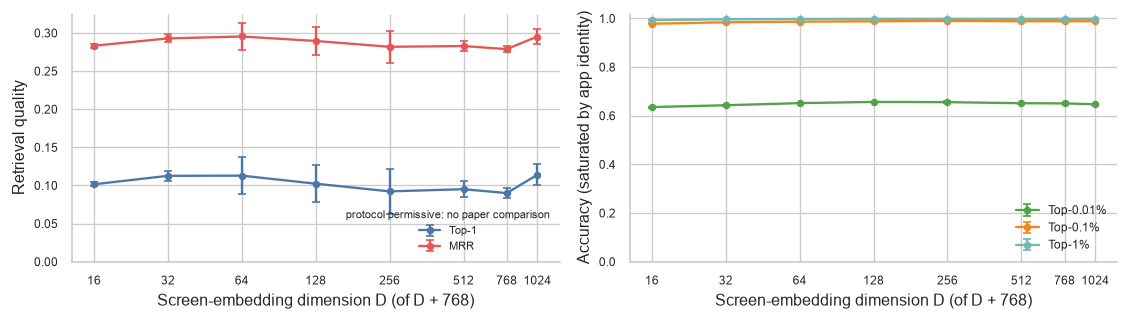

**`h4096`** — protocol permissive, hidden 4096

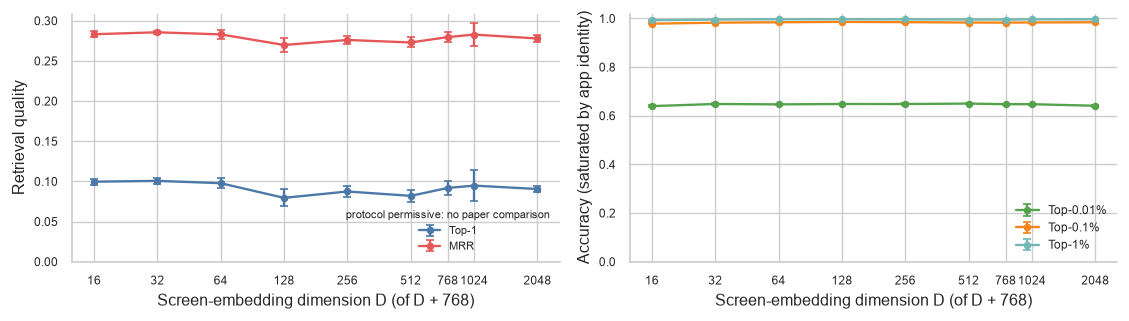

In [4]:
def plot_config(name, summary, meta, matched, noapp=None):
    dims = summary["proj_dim"].to_numpy()
    multi = (summary["n"] > 1).any()
    n_panels = 2 if SHOW_SATURATED_PANEL else 1
    fig, axes = plt.subplots(1, n_panels, figsize=(FIGSIZE[0] * n_panels, FIGSIZE[1]), squeeze=False)
    axes = axes[0]

    def curve(ax, key, color, label, source=summary, reference=True, **style):
        ax.errorbar(source["proj_dim"], source[f"{key}_mean"], yerr=source[f"{key}_std"] if multi else None,
                    color=color, marker="o", markersize=3.5, linewidth=1.4, capsize=2.5, label=label, **style)
        if reference and matched and key in PAPER:
            ax.axhline(PAPER[key], color=color, linestyle=(0, (4, 3)), linewidth=1, alpha=0.7)

    for ax in axes:
        ax.set_xscale("log", base=2)
        ax.set_xticks(dims)
        ax.set_xticklabels([str(d) for d in dims], fontsize=7)
        ax.minorticks_off()
        ax.set_xlabel("Screen-embedding dimension D (of D + 768)")
        ax.tick_params(labelsize=7)

    curve(axes[0], "top1", "#4C78A8", "Top-1")
    curve(axes[0], "mrr", "#E45756", "MRR")
    if noapp is not None:
        curve(axes[0], "top1", "#4C78A8", "Top-1, screen vector alone", source=noapp, reference=False, linestyle=":", alpha=0.8)
        curve(axes[0], "mrr", "#E45756", "MRR, screen vector alone", source=noapp, reference=False, linestyle=":", alpha=0.8)
    axes[0].set_ylim(0, None)
    axes[0].set_ylabel("Retrieval quality")
    axes[0].legend(frameon=False, fontsize=6.5, loc="lower right",
                   title="dashed: paper Top-1" if matched else f"protocol {meta.get('protocol')}: no paper comparison",
                   title_fontsize=6.5)

    if SHOW_SATURATED_PANEL:
        curve(axes[1], "top001pct", "#54A24B", "Top-0.01%")
        curve(axes[1], "top01pct", "#F58518", "Top-0.1%")
        curve(axes[1], "top1pct", "#72B7B2", "Top-1%")
        axes[1].set_ylim(0, 1.02)
        axes[1].set_ylabel("Accuracy (saturated by app identity)")
        axes[1].legend(frameon=False, fontsize=7, loc="lower right")

    fig.tight_layout()
    fig.savefig(PDF_DIR / f"dimension_sweep_{name}.pdf", bbox_inches="tight")
    fig.savefig(PDF_DIR / f"dimension_sweep_{name}.png", bbox_inches="tight")
    display(Markdown(f"**`{name}`** — protocol {meta.get('protocol')}, hidden {meta.get('hidden_dim')}"))
    plt.show()


for name, summary in summaries.items():
    plot_config(name, summary, configs[name]["meta"], configs[name]["matched"], summaries_noapp.get(name))

## 4. Hidden-width comparison

For every protocol that was swept with more than one projector hidden width, the curves are overlaid (solid = recipe width 1024, dashed = other widths) and the per-dimension differences are tabulated. The hidden layer is internal to the projector and never part of the stored D-dimensional embedding, but it changes the projector's capacity (about 5 M parameters at 1024 versus 20 M at 4096 for D = 768). This comparison is a **within-protocol** robustness check: it was run under the permissive protocol only, and is deliberately not repeated under strict (at every shared dimension the two widths differ by less than the seed SD, and D = 2048 adds nothing). A protocol listed below with a single width is therefore by design, not an omission.

### protocol `permissive` — hidden widths 1024, 4096

D,n (h1024),Top-1 (h1024),Top-1 SD (h1024),MRR (h1024),MRR SD (h1024),n (h4096),Top-1 (h4096),Top-1 SD (h4096),MRR (h4096),MRR SD (h4096),Δ Top-1 (h4096 − h1024),Δ MRR (h4096 − h1024)
16,3.000000,0.1015,0.0029,0.2833,0.0025,3,0.0996,0.0039,0.2832,0.0035,-0.0019,-0.0000
32,3.000000,0.1126,0.0069,0.2928,0.0053,3,0.1006,0.0037,0.2857,0.0016,-0.0120,-0.0072
64,3.000000,0.1128,0.0242,0.2954,0.0176,3,0.0977,0.0066,0.2830,0.0052,-0.0151,-0.0123
128,3.000000,0.1023,0.0246,0.2895,0.0179,3,0.0795,0.0107,0.2698,0.0088,-0.0228,-0.0197
256,3.000000,0.0922,0.0294,0.2818,0.0212,3,0.0874,0.0069,0.2761,0.0052,-0.0048,-0.0057
512,3.000000,0.0951,0.0106,0.2828,0.0070,3,0.0820,0.0070,0.2730,0.0062,-0.0131,-0.0099
768,3.000000,0.0900,0.0061,0.2788,0.0037,3,0.0918,0.0088,0.2797,0.0064,+0.0019,+0.0009
1024,3.000000,0.1140,0.0135,0.2953,0.0100,3,0.0947,0.0194,0.2828,0.0147,-0.0193,-0.0125
2048,–,–,–,–,–,3,0.0905,0.0042,0.2779,0.0038,–,–


largest |Δ Top-1| between widths on the 8 shared dimensions: 0.0228 (largest seed SD: 0.0294)


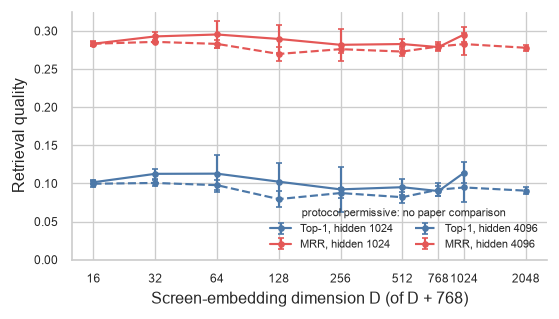

In [5]:
by_protocol = {}
for name, c in configs.items():
    by_protocol.setdefault(str(c["meta"].get("protocol")), []).append(name)

for protocol, names in sorted(by_protocol.items()):
    names = sorted(names, key=lambda n: int(configs[n]["meta"].get("hidden_dim") or 0))
    widths = {n: int(configs[n]["meta"].get("hidden_dim") or 0) for n in names}
    matched = configs[names[0]]["matched"]
    if len(names) < 2:
        display(Markdown(f"### protocol `{protocol}` — one hidden width ({widths[names[0]]}) **by design**: the width "
                         "comparison is a within-protocol check and was run under the permissive protocol only."))
        continue
    display(Markdown(f"### protocol `{protocol}` — hidden widths {', '.join(str(widths[n]) for n in names)}"))

    # Side-by-side table on the shared dimensions, differences relative to the narrowest width.
    base = names[0]
    merged = None
    for n in names:
        part = summaries[n][["proj_dim", "n", "top1_mean", "top1_std", "mrr_mean", "mrr_std"]].copy()
        part.columns = ["D", f"n (h{widths[n]})", f"Top-1 (h{widths[n]})", f"Top-1 SD (h{widths[n]})",
                        f"MRR (h{widths[n]})", f"MRR SD (h{widths[n]})"]
        merged = part if merged is None else merged.merge(part, on="D", how="outer")
    for n in names[1:]:
        merged[f"Δ Top-1 (h{widths[n]} − h{widths[base]})"] = merged[f"Top-1 (h{widths[n]})"] - merged[f"Top-1 (h{widths[base]})"]
        merged[f"Δ MRR (h{widths[n]} − h{widths[base]})"] = merged[f"MRR (h{widths[n]})"] - merged[f"MRR (h{widths[base]})"]
    merged = merged.sort_values("D")
    merged.to_csv(PDF_DIR / f"dimension_sweep_hidden_comparison_{protocol}.csv", index=False)
    fmt = {c: "{:+.4f}" if c.startswith("Δ") else "{:.4f}" for c in merged.columns if c != "D" and not c.startswith("n (")}
    display(merged.style.format(fmt, na_rep="–").hide(axis="index"))
    shared = merged.dropna(subset=[f"Top-1 (h{widths[n]})" for n in names])
    if len(shared):
        gaps = [shared[f"Δ Top-1 (h{widths[n]} − h{widths[base]})"].abs().max() for n in names[1:]]
        sds = max(shared[f"Top-1 SD (h{widths[n]})"].max() for n in names)
        print(f"largest |Δ Top-1| between widths on the {len(shared)} shared dimensions: {max(gaps):.4f} "
              f"(largest seed SD: {sds:.4f})")

    # Overlay figure: Top-1 and MRR, one line style per width.
    styles = ["-", "--", ":", "-."]
    fig, ax = plt.subplots(figsize=FIGSIZE)
    for style, n in zip(styles, names):
        summary = summaries[n]
        multi = (summary["n"] > 1).any()
        for key, color, label in (("top1", "#4C78A8", "Top-1"), ("mrr", "#E45756", "MRR")):
            ax.errorbar(summary["proj_dim"], summary[f"{key}_mean"],
                        yerr=summary[f"{key}_std"] if multi else None, color=color, linestyle=style,
                        marker="o", markersize=3, linewidth=1.3, capsize=2, label=f"{label}, hidden {widths[n]}")
    if matched:
        ax.axhline(PAPER["top1"], color="#4C78A8", linestyle=(0, (1, 2)), linewidth=1, alpha=0.7)
    all_dims = sorted({int(d) for n in names for d in summaries[n]["proj_dim"]})
    ax.set_xscale("log", base=2)
    ax.set_xticks(all_dims)
    ax.set_xticklabels([str(d) for d in all_dims], fontsize=7)
    ax.minorticks_off()
    ax.set_ylim(0, None)
    ax.set_xlabel("Screen-embedding dimension D (of D + 768)")
    ax.set_ylabel("Retrieval quality")
    ax.tick_params(labelsize=7)
    ax.legend(frameon=False, fontsize=6.5, loc="lower right", ncol=2,
              title="dotted: paper Top-1" if matched else f"protocol {protocol}: no paper comparison", title_fontsize=6.5)
    fig.tight_layout()
    fig.savefig(PDF_DIR / f"dimension_sweep_hidden_comparison_{protocol}.pdf", bbox_inches="tight")
    fig.savefig(PDF_DIR / f"dimension_sweep_hidden_comparison_{protocol}.png", bbox_inches="tight")
    plt.show()

## 5. Individual runs and provenance

Every (dimension, seed) run with its evaluated population, so a suspicious point can be traced to its log in `dimension_sweep/logs/`. `trained_in_sweep = False` marks a point whose checkpoints already existed and were reused: for D = 768 at the recipe width and seed 42, that is the canonical run behind the numbers in `SUMMARY.md`. Runs recorded before that field existed show "–".

In [6]:
for name, c in configs.items():
    display(Markdown(f"**`{name}`**"))
    cols = ["proj_dim", "seed", "top1", "mrr", "noapp_top1", "noapp_mrr", "top001pct", "top01pct", "top1pct", "top5pct",
            "nrmse", "n_traces", "n_screens_in_traces", "n_instances", "trained_in_sweep", "completed_at"]
    fmt = {k: "{:.4f}" for k in (*sweep.METRIC_KEYS, "noapp_top1", "noapp_mrr")}
    display(c["runs"][cols].style.format(fmt, na_rep="–").hide(axis="index"))
    meta = {k: v for k, v in c["meta"].items() if k != "trace_index_meta"}
    meta["trace_index_coverage"] = (c["meta"].get("trace_index_meta") or {}).get("coverage")
    print(json.dumps(meta, indent=2))

print("\nfiles in", PDF_DIR.relative_to(ROOT))
for path in sorted(PDF_DIR.iterdir()):
    print(f"  {path.name:45s} {path.stat().st_size / 1024:8.1f} KB")

**`permissive`**

proj_dim,seed,top1,mrr,noapp_top1,noapp_mrr,top001pct,top01pct,top1pct,top5pct,nrmse,n_traces,n_screens_in_traces,n_instances,trained_in_sweep,completed_at
16,42,0.1044,0.2855,–,–,0.6354,0.9796,0.9938,0.9983,0.4827,7164,61681,54517,–,2026-09-17T21:52:24
16,43,0.1015,0.2838,–,–,0.6375,0.9779,0.9929,0.9979,0.4789,7164,61681,54517,–,2026-09-18T18:42:49
16,44,0.0987,0.2805,–,–,0.6339,0.9768,0.9918,0.9973,0.4438,7164,61681,54517,–,2026-09-18T19:21:12
32,42,0.1191,0.2985,–,–,0.6437,0.9855,0.9973,0.9995,0.5766,7164,61681,54517,–,2026-09-17T22:31:27
32,43,0.1053,0.2879,–,–,0.6437,0.9838,0.9960,0.9992,0.5405,7164,61681,54517,–,2026-09-18T20:00:04
32,44,0.1134,0.2921,–,–,0.6418,0.9833,0.9964,0.9993,0.5353,7164,61681,54517,–,2026-09-18T20:38:50
64,42,0.1284,0.3073,–,–,0.6528,0.9884,0.9984,0.9999,0.5963,7164,61681,54517,–,2026-09-17T23:11:08
64,43,0.1252,0.3036,–,–,0.6511,0.9868,0.9980,0.9998,0.5925,7164,61681,54517,–,2026-09-18T21:18:36
64,44,0.0849,0.2752,–,–,0.6514,0.9844,0.9965,0.9994,0.5168,7164,61681,54517,–,2026-09-18T21:56:33
128,42,0.0949,0.2837,–,–,0.6559,0.9868,0.9976,0.9998,0.5768,7164,61681,54517,–,2026-09-17T23:50:49


{
  "recipe": "9_train_joint.py -> 6_generate_app_context_embeddings.py -> 4_evaluate_screen_prediction.py",
  "protocol": "permissive",
  "hidden_dim": 1024,
  "raw_embeddings_dir": "embeddings_4096_last",
  "trace_index": "trace_layout_index.csv",
  "seeds": [
    42,
    43,
    44
  ],
  "git_revision": "c5e4006",
  "sample_fraction": null,
  "updated_at": "2026-09-18T18:04:13",
  "trace_index_coverage": 0.9984304492838925
}


**`h4096`**

proj_dim,seed,top1,mrr,noapp_top1,noapp_mrr,top001pct,top01pct,top1pct,top5pct,nrmse,n_traces,n_screens_in_traces,n_instances,trained_in_sweep,completed_at
16,42,0.1041,0.2873,–,–,0.6424,0.9775,0.9922,0.9976,0.4519,7164,61681,54517,–,2026-09-17T21:52:41
16,43,0.0978,0.2811,–,–,0.6359,0.9810,0.9940,0.9980,0.4243,7164,61681,54517,–,2026-09-18T18:42:06
16,44,0.0969,0.2813,–,–,0.6402,0.9766,0.9912,0.9969,0.4472,7164,61681,54517,–,2026-09-18T19:20:39
32,42,0.1003,0.2853,–,–,0.6455,0.9823,0.9957,0.9991,0.4964,7164,61681,54517,–,2026-09-17T22:32:52
32,43,0.0971,0.2843,–,–,0.6545,0.9835,0.9950,0.9988,0.4715,7164,61681,54517,–,2026-09-18T20:00:05
32,44,0.1045,0.2874,–,–,0.6451,0.9818,0.9954,0.9990,0.5179,7164,61681,54517,–,2026-09-18T20:39:04
64,42,0.1052,0.2887,–,–,0.6473,0.9850,0.9969,0.9995,0.5282,7164,61681,54517,–,2026-09-17T23:12:37
64,43,0.0951,0.2818,–,–,0.6497,0.9848,0.9961,0.9991,0.5015,7164,61681,54517,–,2026-09-18T21:17:25
64,44,0.0929,0.2786,–,–,0.6429,0.9830,0.9962,0.9994,0.5050,7164,61681,54517,–,2026-09-18T21:57:28
128,42,0.0747,0.2663,–,–,0.6489,0.9862,0.9970,0.9994,0.4474,7164,61681,54517,–,2026-09-17T23:52:12


{
  "recipe": "9_train_joint.py -> 6_generate_app_context_embeddings.py -> 4_evaluate_screen_prediction.py",
  "protocol": "permissive",
  "hidden_dim": 4096,
  "raw_embeddings_dir": "embeddings_4096_last",
  "trace_index": "trace_layout_index.csv",
  "seeds": [
    42,
    43,
    44
  ],
  "git_revision": "c5e4006",
  "sample_fraction": null,
  "updated_at": "2026-09-18T18:04:13",
  "trace_index_coverage": 0.9984304492838925
}

files in graphics/dimension_sweep
  dimension_sweep_h4096.csv                          2.5 KB
  dimension_sweep_h4096.pdf                         30.7 KB
  dimension_sweep_h4096.png                         59.6 KB
  dimension_sweep_h4096.tex                          2.3 KB
  dimension_sweep_hidden_comparison_permissive.csv      1.9 KB
  dimension_sweep_hidden_comparison_permissive.pdf     28.5 KB
  dimension_sweep_hidden_comparison_permissive.png     41.5 KB
  dimension_sweep_permissive.csv                     2.2 KB
  dimension_sweep_permissive.pdf           